# 02 – Bivariate Analysis

## Credit Risk – Probability of Default

# 1. Libs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets

from pathlib import Path
from IPython.display import display, HTML
from IPython.display import display_html
from ucimlrepo import fetch_ucirepo

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# 2. Data Loading

Loading the Default of Credit Card Clients dataset from the UCI Machine Learning Repository.

In [2]:
df = pd.read_parquet("../data/processed/credit_default_eda.parquet")

# 3. Payment Status vs. Credit Default

In [3]:
payment_status_columns = [
    "PAY_1", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

tables = []

for col in payment_status_columns:
    result = (
        df.groupby(col)["Y"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "number_of_clients",
            "mean": "default_rate"
        })
    )

    result["default_rate"] *= 100

    output = widgets.Output(
        layout=widgets.Layout(width="300px")
    )

    with output:
        print(col)
        display(result.round(2))

    tables.append(output)

display(
    widgets.VBox(
        [
            widgets.HBox(tables[:3], layout=widgets.Layout(gap="30px")),
            widgets.HBox(tables[3:], layout=widgets.Layout(gap="30px"))
        ],
        layout=widgets.Layout(gap="30px")
    )
)

__We have now uncovered one of the most significant findings from our EDA: payment delinquency history is strongly associated with the probability of default.__

Consider PAY_0, which represents September 2005: customers with a value of 2 exhibit a default rate of 69.14%, compared to only 12.81% for those with a value of 0.

This represents a difference of 56.33 percentage points.

__This suggests that recent payment delinquency history may be among the most relevant pieces of information for the model.__

__And this pattern persists across other time periods.__

There is a strong and consistent association between the code 2 and high default rates.

We also observe that the contrast between codes 0 and 2 is most pronounced in the most recent period (PAY_0).

This aligns with the hypothesis that recent delinquencies carry more predictive information regarding default in the following month. However, we cannot yet conclude that PAY_0 will necessarily be the most important variable in the model.

__A note of caution regarding rare categories__

Consider a few examples:

- PAY_3 = 1: only 4 customers.
- PAY_4 = 1: only 2 customers.
- PAY_5 = 8: only 1 customer.
- PAY_6 = 8: only 2 customers.

A 100% default rate within a group of only two customers does not imply that all future customers with this characteristic will default.

We should not interpret extreme rates from very small groups as reliable risk estimates.

__But, reggarding our model, we already have exploratory evidence that payment history contains a significant predictive signal.__

However, we still need to determine how to represent these variables:

- Keep them as integers.
- Treat them as categories.
- Create derived variables, such as the number of periods with delinquencies.

__We do not need to decide this just yet. We can compare different representations during modeling.__

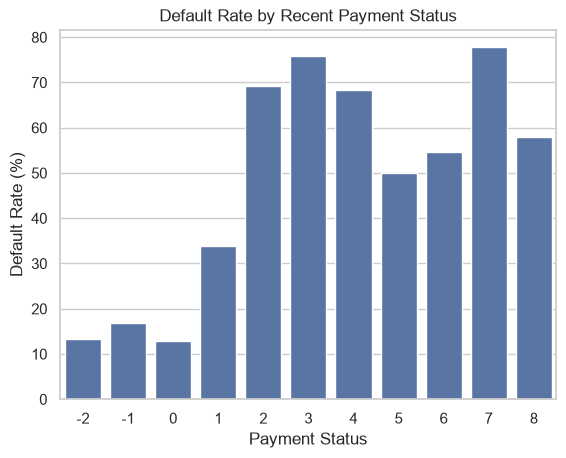

In [6]:
payment_default_rates = (
    df.groupby("PAY_1")["Y"]
      .agg(["count", "mean"])
      .reset_index()
)

payment_default_rates["mean"] *= 100

sns.barplot(
    data=payment_default_rates,
    x="PAY_1",
    y="mean"
)

plt.title("Default Rate by Recent Payment Status")
plt.xlabel("Payment Status")
plt.ylabel("Default Rate (%)")
plt.show()

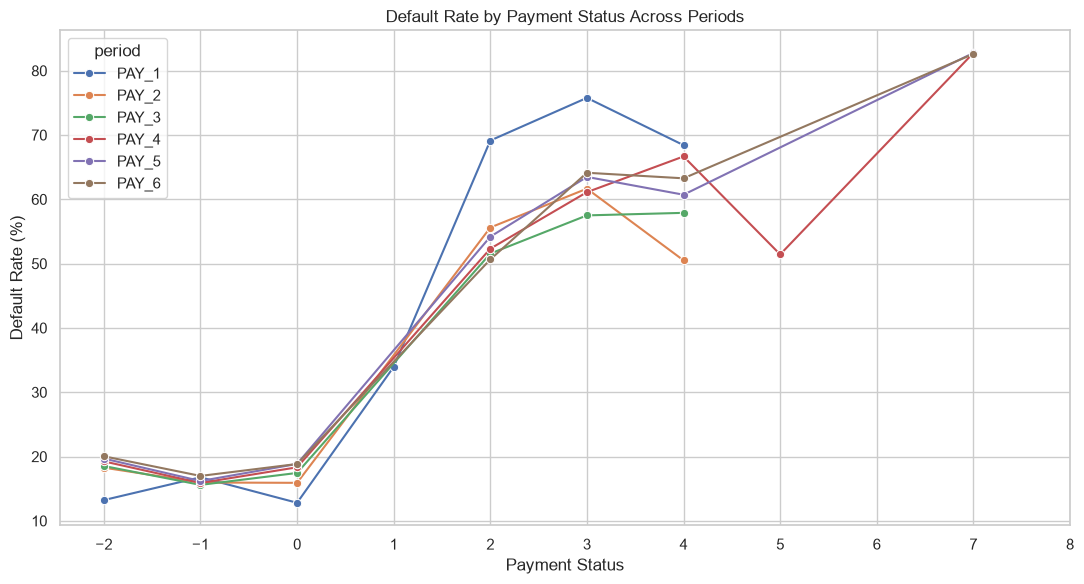

In [7]:
payment_status_columns = [
    "PAY_1", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

results = []

for col in payment_status_columns:
    rates = (
        df.groupby(col)["Y"]
        .agg(["count", "mean"])
        .reset_index()
        .rename(columns={
            col: "payment_status",
            "count": "number_of_clients",
            "mean": "default_rate"
        })
    )

    rates["period"] = col
    rates["default_rate"] *= 100

    results.append(rates)

payment_rates = pd.concat(results, ignore_index=True)

# Focus on categories with at least 30 observations
plot_data = payment_rates[
    payment_rates["number_of_clients"] >= 30
]

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=plot_data,
    x="payment_status",
    y="default_rate",
    hue="period",
    marker="o"
)

plt.title("Default Rate by Payment Status Across Periods")
plt.xlabel("Payment Status")
plt.ylabel("Default Rate (%)")
plt.xticks(range(-2, 9))
plt.tight_layout()
plt.show()

__Payment status variables exhibit a strong association with credit default.__ 

Default rates increase substantially for delinquency codes of 2 or higher, particularly in the most recent period (PAY_0). Special codes (-2, -1, 0) do not exhibit a clear ordinal relationship, while rare delinquency categories produce unstable default-rate estimates.

In [10]:
transition_matrix = pd.crosstab(
    df["PAY_2"],
    df["PAY_1"]
)

display(transition_matrix)

PAY_1,-2,-1,0,1,2,3,4,5,6,7,8
PAY_2,,,,,,,,,,,
-2,2561,0,0,1221,0,0,0,0,0,0,0
-1,193,4641,478,612,126,0,0,0,0,0,0
0,0,603,14259,3,865,0,0,0,0,0,0
1,0,0,0,28,0,0,0,0,0,0,0
2,5,387,0,1672,1591,272,0,0,0,0,0
3,0,47,0,109,71,41,58,0,0,0,0
4,0,5,0,32,14,8,15,25,0,0,0
5,0,3,0,7,0,1,3,0,11,0,0
6,0,0,0,2,0,0,0,1,0,9,0


__The transition matrix provides strong empirical evidence that positive payment status codes represent consecutive months of payment delay.__ 

The observed transitions from codes 2→3, 3→4, 4→5, and subsequent levels are consistent with the accumulation of delinquency over consecutive billing periods. However, these transitions do not necessarily imply a complete absence of payments, as partial payments may occur while an account remains delinquent.

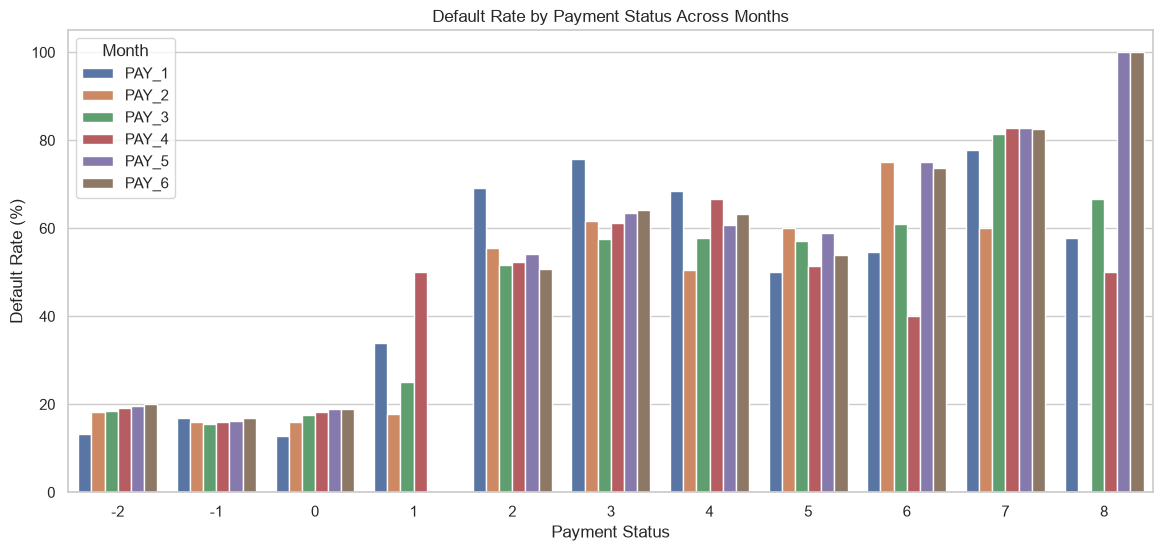

In [11]:
payment_columns = ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

payment_default_rates = (
    df.melt(
        id_vars="Y",
        value_vars=payment_columns,
        var_name="Month",
        value_name="Payment_Status"
    )
    .groupby(["Month", "Payment_Status"])["Y"]
    .agg(["count", "mean"])
    .reset_index()
)

payment_default_rates["mean"] *= 100

plt.figure(figsize=(14, 6))

sns.barplot(
    data=payment_default_rates,
    x="Payment_Status",
    y="mean",
    hue="Month"
)

plt.title("Default Rate by Payment Status Across Months")
plt.xlabel("Payment Status")
plt.ylabel("Default Rate (%)")
plt.legend(title="Month")
plt.show()

# 4. Demographic Variables vs. Credit Default

In [16]:
import ipywidgets as widgets
from IPython.display import display

demographic_columns = ["EDUCATION", "MARRIAGE", "SEX"]

outputs = []

for col in demographic_columns:

    output = widgets.Output()

    with output:
        result = (
            df.groupby(col)["Y"]
            .agg(["count", "mean"])
            .rename(columns={
                "count": "number_of_clients",
                "mean": "default_rate"
            })
        )

        result["default_rate"] *= 100

        print(col)
        display(result.round(2))

    outputs.append(output)

# Display all three tables side by side
display(widgets.HBox(
    outputs,
    layout=widgets.Layout(
        width="100%",
        justify_content="space-between",
        gap="20px"
    )
))

__Key Findings — Demographic Variables vs. Credit Default__

__Education__

Default rates increase from graduate school (19.23%) to university (23.73%) and high school (25.16%).

Undocumented categories (0, 5, 6) are present and will be investigated during preprocessing.

Categories with small sample sizes require cautious interpretation.

__Marital Status__

Married clients exhibit a higher default rate (23.47%) than single clients (20.93%).

Category 0 is undocumented and contains only 54 observations.

__Sex__

Male clients exhibit a default rate of 24.17%, compared with 20.78% for female clients.

Sex is a sensitive demographic characteristic and requires fairness and regulatory considerations before inclusion in a credit decision model.

Preprocessing Considerations

Preserve observations with undocumented categories.

Consider grouping undocumented codes into an Unknown category.

Evaluate categorical encoding strategies during model development.

Avoid using observed default rates alone to determine category groupings.

__Conclusion__

__Demographic variables exhibit associations with credit default. However, these relationships do not establish causality or automatically justify their use in credit decision-making.__

# 5. Default Rate vs. Credit Limit

In [17]:
limit_bins = pd.qcut(
    df["LIMIT_BAL"],
    q=10,
    duplicates="drop"
)

result = (
    df.groupby(limit_bins, observed=True)["Y"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "number_of_clients",
        "mean": "default_rate"
    })
)

result["default_rate"] *= 100

display(result.round(2))

,number_of_clients,default_rate
LIMIT_BAL,,
"(9999.999, 30000.0]",4081,35.85
"(30000.0, 50000.0]",3595,27.18
"(50000.0, 70000.0]",1556,28.47
"(70000.0, 100000.0]",3266,24.53
"(100000.0, 140000.0]",2792,22.85
"(140000.0, 180000.0]",3331,17.35
"(180000.0, 210000.0]",2487,17.53
"(210000.0, 270000.0]",2934,16.29
"(270000.0, 360000.0]",3482,15.16


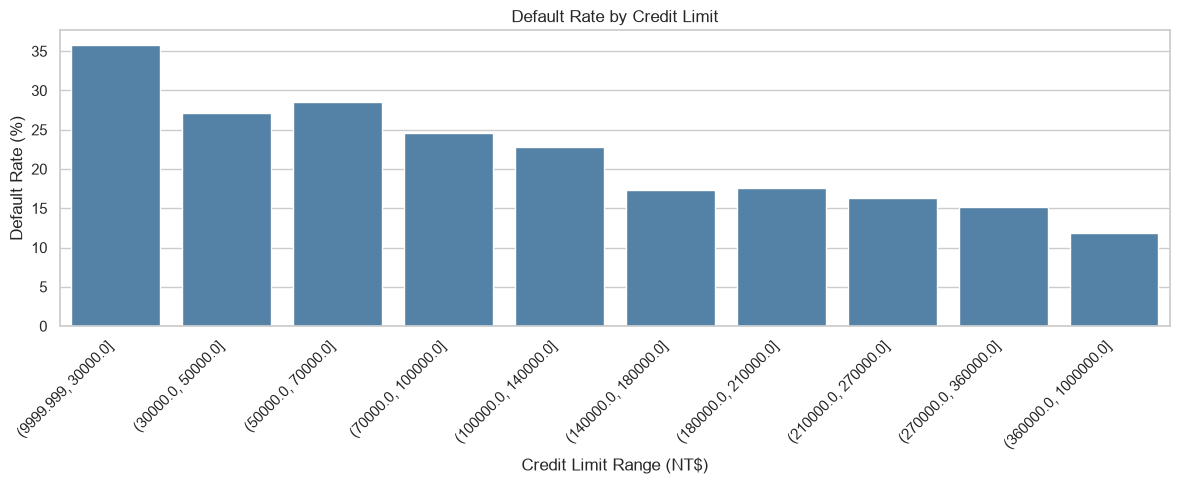

In [18]:
plot_data = result.reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(
    data=plot_data,
    x="LIMIT_BAL",
    y="default_rate",
    color="steelblue"
)

plt.title("Default Rate by Credit Limit")
plt.xlabel("Credit Limit Range (NT$)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

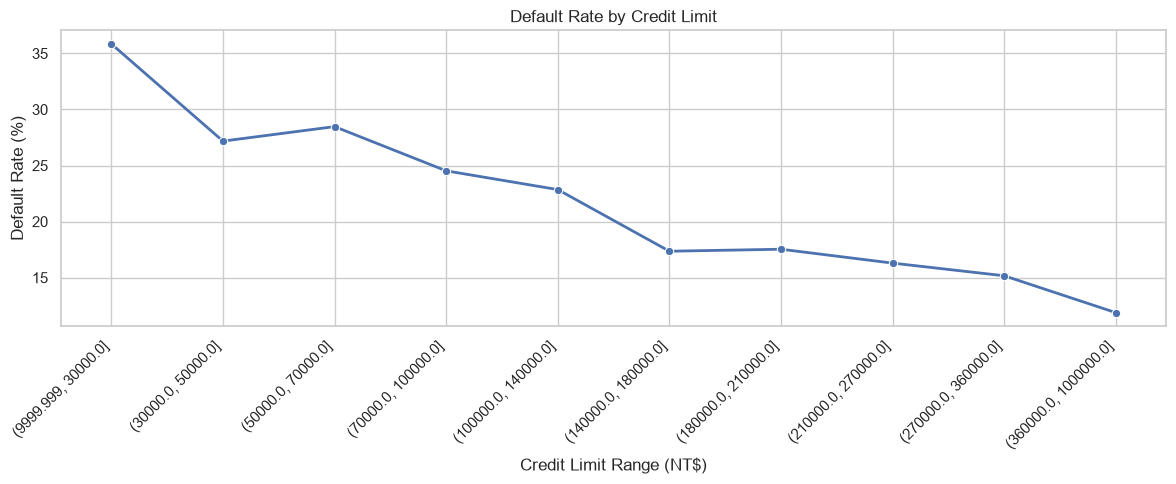

In [22]:
plot_data = result.reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=plot_data,
    x=range(len(plot_data)),
    y="default_rate",
    marker="o",
    linewidth=2
)

plt.xticks(
    ticks=range(len(plot_data)),
    labels=plot_data["LIMIT_BAL"].astype(str),
    rotation=45,
    ha="right"
)

plt.title("Default Rate by Credit Limit")
plt.xlabel("Credit Limit Range (NT$)")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

__Credit limit (LIMIT_BAL) exhibits a strong inverse association with credit default.__

Clients with credit limits between NT$10,000 and NT$30,000 have the highest observed default rate (35.85%).

Clients with credit limits above NT$360,000 have the lowest observed default rate (11.87%).

The difference between these groups is approximately 24 percentage points.

The relationship is predominantly decreasing, although minor fluctuations occur across credit limit ranges.

This association does not imply causation, as credit limits may reflect prior creditworthiness assessments.

__Modeling decision: Retain LIMIT_BAL as a continuous numerical variable. Quantile-based binning was used exclusively for exploratory analysis. No transformation is required at this stage.__

# 6. AGE vs. Credit Default

In [19]:
age_bins = pd.qcut(
    df["AGE"],
    q=10,
    duplicates="drop"
)

age_result = (
    df.groupby(age_bins, observed=True)["Y"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "number_of_clients",
        "mean": "default_rate"
    })
)

age_result["default_rate"] *= 100

display(age_result.round(2))

,number_of_clients,default_rate
AGE,,
"(20.999, 25.0]",3871,26.66
"(25.0, 27.0]",2733,20.71
"(27.0, 29.0]",3014,19.87
"(29.0, 31.0]",2612,19.26
"(31.0, 34.0]",3466,19.36
"(34.0, 37.0]",3262,21.74
"(37.0, 40.0]",2768,20.95
"(40.0, 43.0]",2288,22.73
"(43.0, 49.0]",3306,23.53


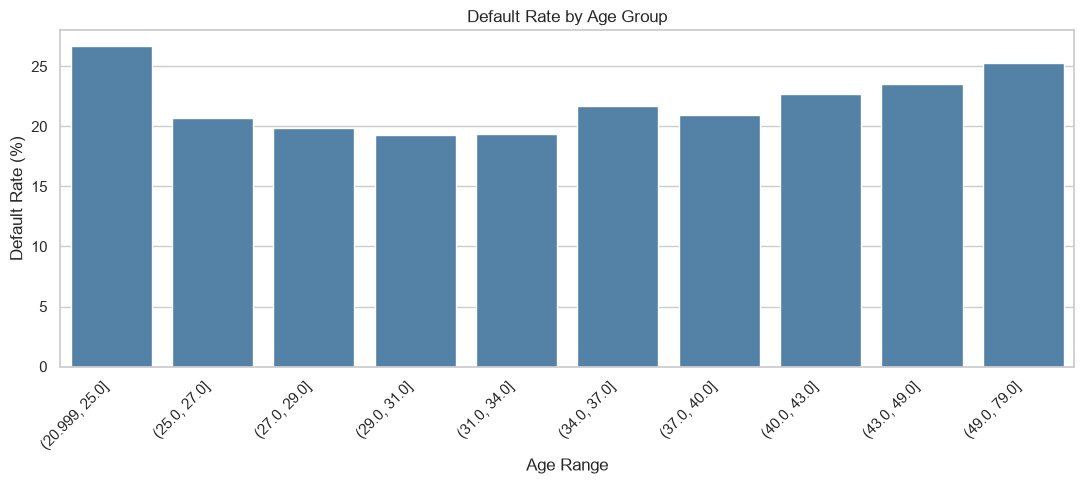

In [20]:
plot_data = age_result.reset_index()

plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_data,
    x="AGE",
    y="default_rate",
    color="steelblue"
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Range")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

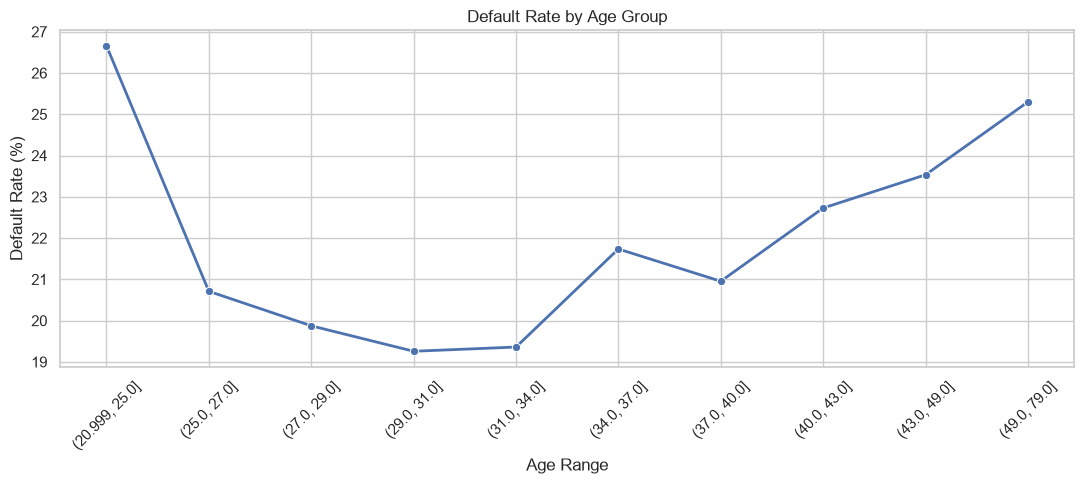

In [21]:
plot_data = age_result.reset_index()

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=plot_data,
    x=range(len(plot_data)),
    y="default_rate",
    marker="o",
    linewidth=2
)

plt.xticks(
    ticks=range(len(plot_data)),
    labels=plot_data["AGE"].astype(str),
    rotation=45
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Range")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

__Findings__

- The relationship between age and credit default exhibits an approximately U-shaped pattern.
- Younger clients (21–25 years) have the highest observed default rate (26.66%).
- Clients aged 30–31 have the lowest observed default rate (19.26%).
- Default rates increase again among older clients, reaching 25.30% for the 50–79 age group.
- The difference between the highest and lowest observed default rates is 7.40 percentage points.
- These findings suggest a nonlinear association between age and default, but do not establish causality.
- AGE will remain a numerical variable during initial modeling. Nonlinear effects can be evaluated through tree-based models or appropriate transformations.
- The use of age in operational credit decisions requires fairness and regulatory considerations.

# 8. Default Rate Analysis of Negative Bill Amounts

Comparing default rates between clients with negative and non-negative monthly bill statement amounts to investigate whether negative balances are associated with different credit risk profiles.

In [4]:
target = "Y"

bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]

results = []

for col in bill_columns:

    negative_col = f"{col}_NEGATIVE"
    df[negative_col] = df[col] < 0

    result = (
        df.groupby(negative_col)[target]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "number_of_clients",
            "mean": "default_rate"
        })
    )

    result["default_rate"] *= 100

    results.append(
        f"<h4>{col}</h4>" + result.to_html(float_format=lambda x: f"{x:.2f}")
    )

left_column = "".join(results[:3])
right_column = "".join(results[3:])

html = f"""
<div style="display: flex; gap: 30px;">
    <div style="flex: 1;">{left_column}</div>
    <div style="flex: 1;">{right_column}</div>
</div>
"""

display_html(html, raw=True)

,number_of_clients,default_rate
BILL_AMT1_NEGATIVE,,
False,29410,22.19
True,590,18.47
,number_of_clients,default_rate
BILL_AMT2_NEGATIVE,,
False,29331,22.19
True,669,18.98
,number_of_clients,default_rate
BILL_AMT3_NEGATIVE,,
False,29345,22.17


__We observe a consistent pattern: negative invoice amounts are associated with a lower default rate within this sample.__

__This could be consistent with the hypothesis that these customers hold credit balances in their accounts. However, it remains unclear whether this characteristic truly reflects distinct financial behavior or if it is linked to other variables.__

__We must also take into account that these groups are small, representing approximately 2% of customers in each period.__

__My decision for now: keep the negative values. We have no justification for removing or replacing them.__

__Later, let's also create a feature based on negative bill amounts that could be useful for our model later.__